<Axes: xlabel='단지명', ylabel='거래금액(만원)'>

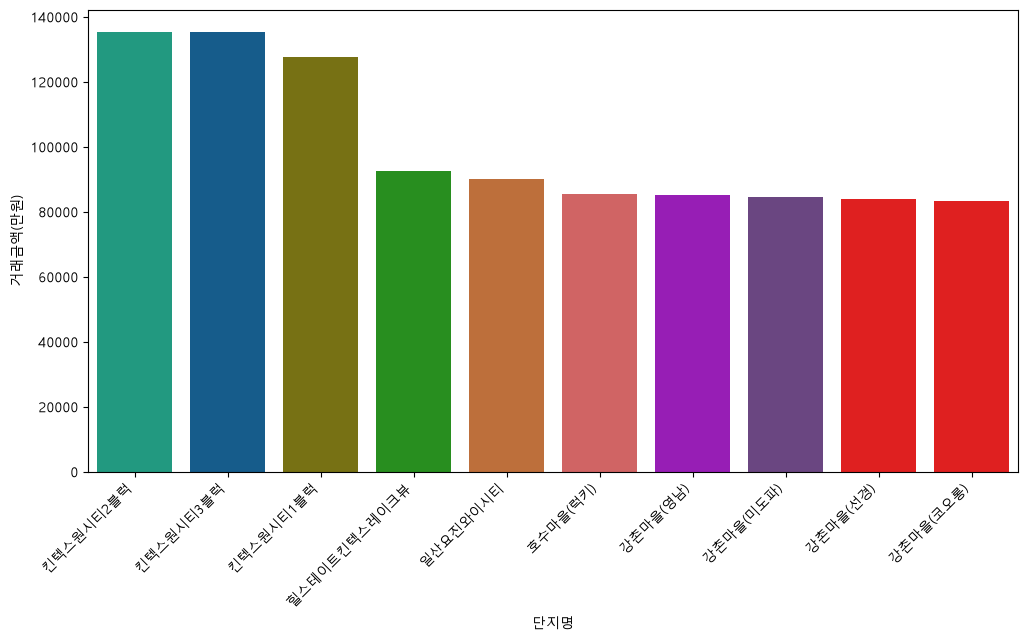

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["font.family"]="Malgun Gothic"

df = pd.read_csv("apt.csv",encoding="cp949",thousands=",",skiprows=15)
result = df.groupby("단지명",as_index=False)["거래금액(만원)"].mean()
result = result.sort_values("거래금액(만원)", ascending=False).head(10)
plt.figure(figsize=(12,6))
plt.xticks(rotation=45,ha="right")
colors=["#0ead8b","#03609e","#887f03","#19a00d","#d36a25","#e25252","#a605ce","#6c3c8b","#ff0000","#ff0000",]
# sns.barplot(data=result,x="단지명",y="거래금액(만원)", hue="단지명",palette="Set2")
sns.barplot(data=result,x="단지명",y="거래금액(만원)", hue="단지명",palette=colors)




Text(0.5, 1.0, '아파트 면적과 거래금액의 관계')

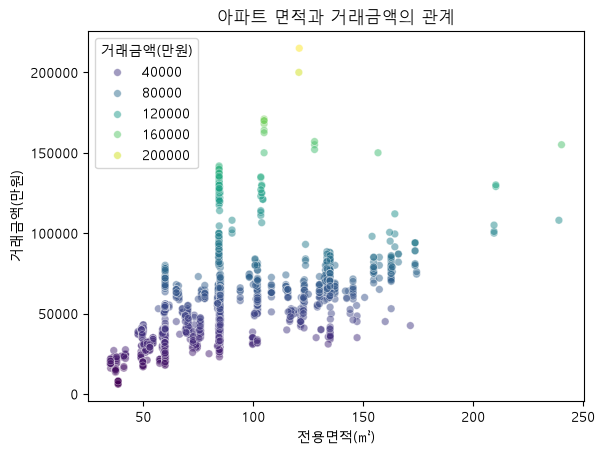

In [20]:
sns.scatterplot(data=df,
                x="전용면적(㎡)",
                y="거래금액(만원)", 
                # color="purple",
                hue="거래금액(만원)",
                palette="viridis",
                alpha=0.5,
                s=30
                )
plt.title("아파트 면적과 거래금액의 관계")

<Axes: xlabel='거래금액(만원)', ylabel='Density'>

C:\Users\tjoeunis205\AppData\Roaming\Python\Python314\site-packages\IPython\core\events.py:101: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  func(*args, **kwargs)
C:\Users\tjoeunis205\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


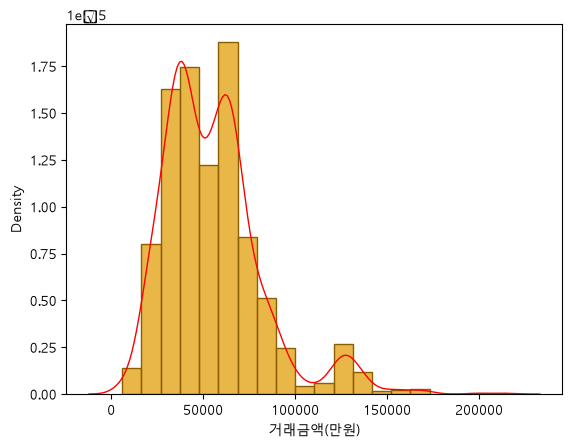

In [28]:
sns.histplot(data=df,
             x="거래금액(만원)",
             bins=20,
             color="#e29e0a",
             kde=False,
             edgecolor="#8a5f02",stat="density")
sns.kdeplot(data=df,x="거래금액(만원)",color="red", linewidth=1)

In [ ]:
columns=["거래금액(만원)","전용면적(㎡)","층","건축년도"]
result = df[columns].copy()
for column in columns:
    result[column] = pd.to_numeric(
                        result[column]
                        .astype(str)
                        .replace(",","",regex=False)
                        ,errors="coerce")
corr = result.corr()    
sns.heatmap(corr,annot=True,cmap="coolwarm",vmax=1, vmin=-1)

KeyError: "['전용면적(전용면적(㎡))'] not in index"